# Project 4: Heart Disease Diagnostic Tool (Binary Classification)

**Course:** Machine Learning, Chapter 14 Capstone Project

**Author:** Marzia Binte Iqbal

## Objective
Predict from a patient's clinical measurements whether the patient has **heart disease**. This is a **binary classification** problem with a **small dataset** (a few hundred patients).

**Medical priority:** telling a sick patient that they are healthy (a **false negative**) is much worse than sending a healthy patient for another check (a **false positive**). So the main metric is **Recall** (the share of sick patients we find), together with Precision, F1 and ROC-AUC. This is a learning project, **not a medical device**.

## Dataset
UCI / Kaggle Heart Disease CSV. Expected columns:
`age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal` plus a label column called `target` (or `num`, which is converted to 0/1).

Put the CSV in `/content/heart.csv.csv` or change `DATA_PATH` below.

## Pipeline (matches the capstone guidelines)
| Step | Section |
|---|---|
| 1. Data acquisition & EDA | 1, 3 |
| 2. Preprocessing (missing values, encoding, scaling) | 2, 5 |
| 3. Model selection: baseline + complex models | 5, 6 |
| 4. Hyperparameter tuning (RandomizedSearchCV) | 6 |
| 5. Rigorous evaluation (Recall, F1, ROC-AUC, Confusion Matrix, repeated CV) | 7, 8 |

## Two rules this notebook follows
1. **No data leakage:** duplicate rows are removed **before** splitting (some copies of this dataset contain many duplicated patients, which would put the same patient in both train and test), and imputers, scalers and encoders live inside pipelines so they learn from training data only.
2. **Small data needs care:** a test set of about 60 patients is very noisy, so the final comparison also uses **repeated stratified cross-validation** on all the data.


## 0. Setup

In [ ]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)


def save_fig(name):
    """Save the current figure to figures/ (handy for the PDF report)."""
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     RandomizedSearchCV, cross_val_predict, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             precision_recall_curve, roc_curve)


In [ ]:
# ---- Settings you can change ----
DATA_PATH = os.environ.get("DATA_PATH", "/content/heart.csv")  # path to the CSV file
TEST_SIZE = 0.2        # 20% of the patients are kept for the final test
N_ITER = 25            # number of random-search trials per model
CV_FOLDS = 5           # cross-validation folds for tuning
INVERT_TARGET = False  # set True if your file uses 1 = healthy, 0 = disease (see section 1)


## 1. Data acquisition

In [ ]:
df = pd.read_csv(DATA_PATH, na_values=["?", ""])
print("Raw shape:", df.shape)

# Label column: "target" (0/1) or "num" (0 = healthy, 1-4 = disease)
if "target" not in df.columns and "num" in df.columns:
    df["target"] = (df["num"] > 0).astype(int)
if "target" not in df.columns:
    raise ValueError(f"No 'target' or 'num' column. Columns found: {list(df.columns)}")

features_expected = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal"]
absent = [c for c in features_expected if c not in df.columns]
if absent:
    raise ValueError(f"Missing columns {absent}. Columns found: {list(df.columns)}")

df = df[features_expected + ["target"]].copy()
if INVERT_TARGET:
    df["target"] = 1 - df["target"]

display(df.head())
df.info()
print("\nMissing values per column:")
print(df.isna().sum())
print("\nClass counts (1 = positive class):")
print(df["target"].value_counts().sort_index())


Raw shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target

**Check the meaning of the label.** In the popular Kaggle copy of this dataset the documentation says `target = 1` means disease, but some people report that the values are actually reversed compared with the original UCI data (where 0 = no disease). Compare with the dataset description you downloaded. If your file turns out to use **1 = healthy**, set `INVERT_TARGET = True` above, so that **1 always means disease** in this notebook. All "Recall" numbers below refer to the class labelled 1.

## 2. Preprocessing

In [ ]:
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {n_before - len(df)} duplicate rows ({n_before} -> {len(df)} patients)")

# Numeric measurements vs categorical codes
NUM_FEATURES = ["age", "trestbps", "chol", "thalach", "oldpeak"]
CAT_FEATURES = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
FEATURES = NUM_FEATURES + CAT_FEATURES
TARGET = "target"

# The categorical columns hold codes (0, 1, 2 ...). OneHotEncoder treats each distinct code as its own category,
# so they need no conversion here.

print("Positive class share:", round(df[TARGET].mean(), 3))


Removed 723 duplicate rows (1025 -> 302 patients)
Positive class share: 0.543


## 3. Exploratory data analysis (EDA)

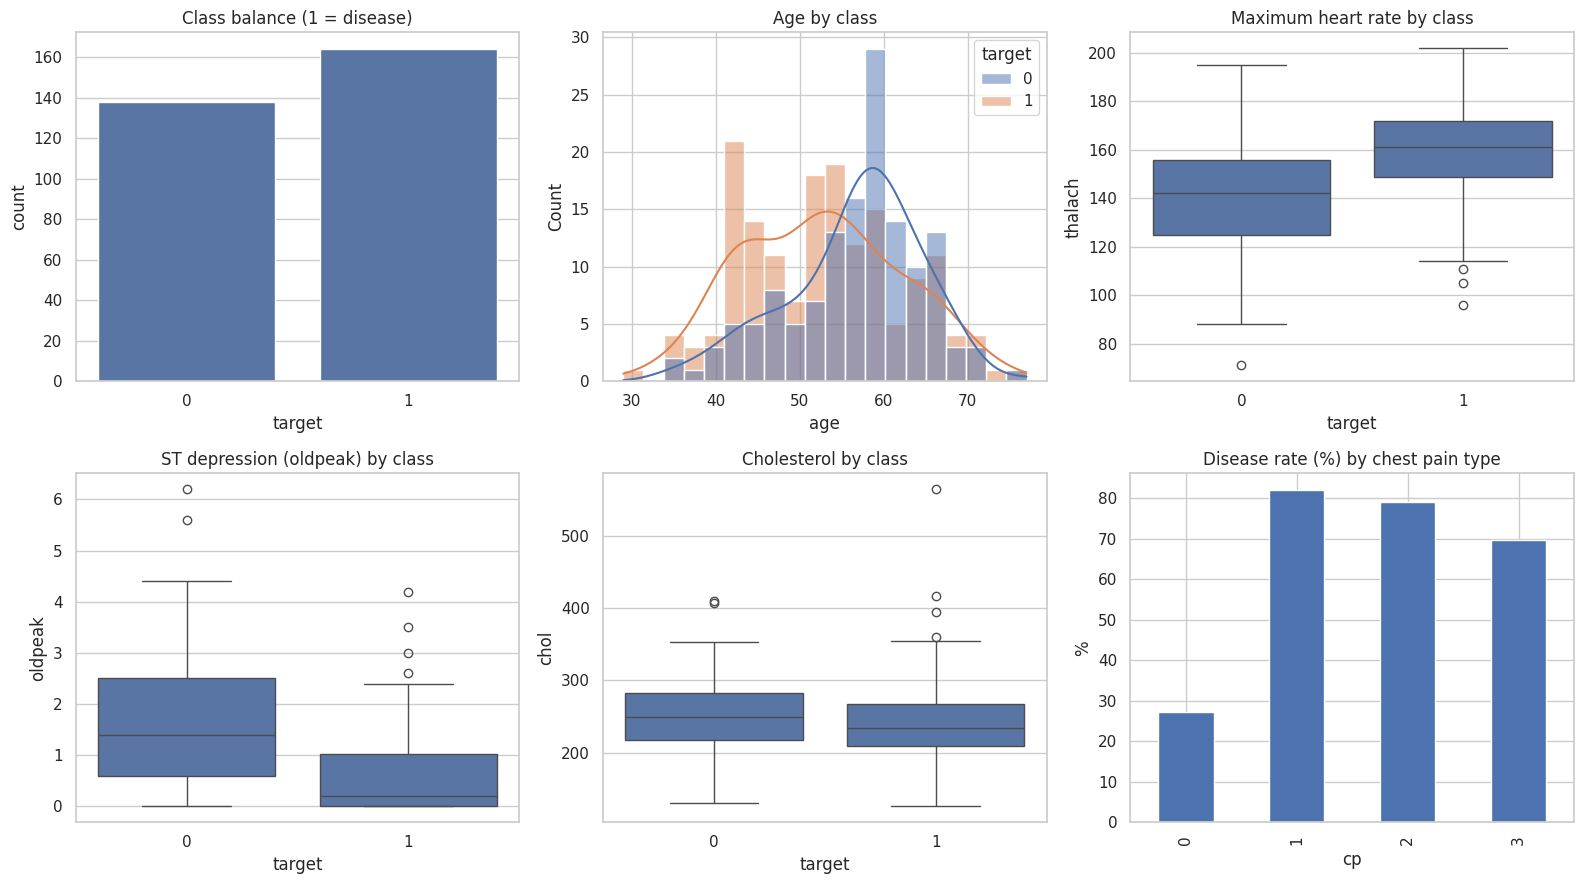

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9))

sns.countplot(x=TARGET, data=df, ax=ax[0, 0])
ax[0, 0].set_title("Class balance (1 = disease)")

sns.histplot(data=df, x="age", hue=TARGET, bins=20, kde=True, ax=ax[0, 1])
ax[0, 1].set_title("Age by class")

sns.boxplot(x=TARGET, y="thalach", data=df, ax=ax[0, 2])
ax[0, 2].set_title("Maximum heart rate by class")

sns.boxplot(x=TARGET, y="oldpeak", data=df, ax=ax[1, 0])
ax[1, 0].set_title("ST depression (oldpeak) by class")

sns.boxplot(x=TARGET, y="chol", data=df, ax=ax[1, 1])
ax[1, 1].set_title("Cholesterol by class")

(df.groupby("cp")[TARGET].mean().mul(100)).plot(kind="bar", ax=ax[1, 2])
ax[1, 2].set_title("Disease rate (%) by chest pain type")
ax[1, 2].set_ylabel("%")

save_fig("heart_eda_overview")
plt.show()


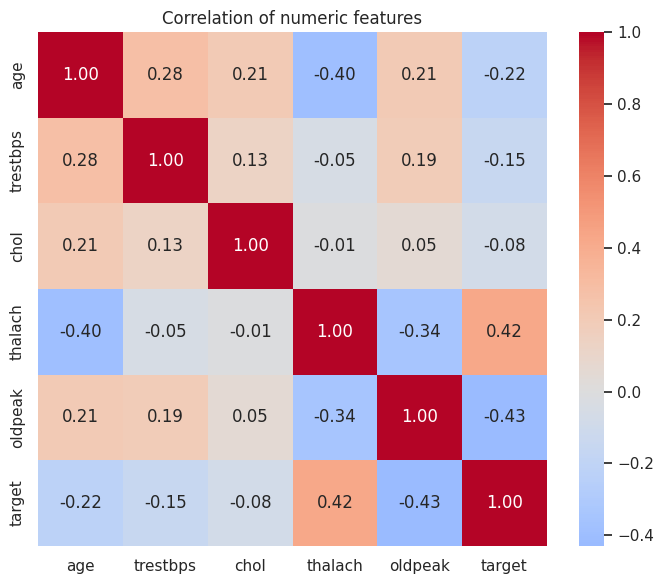

In [ ]:
num_corr = df[NUM_FEATURES + [TARGET]].astype(float).corr()
plt.figure(figsize=(7, 6))
sns.heatmap(num_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of numeric features")
save_fig("heart_correlation")
plt.show()


### EDA insights
1. **The file has many duplicate rows.** There are 1,025 rows, but 723 are exact duplicates, so only 302 distinct patients remain. The duplicates were removed before splitting, so the same patient cannot be in both the training and the test set.

2. **The classes are roughly balanced.** There are 164 patients with `target = 1` (54.3%) and 138 with `target = 0`. There are no missing values.
3. **Maximum heart rate (`thalach`) is higher for `target = 1`.** The median is about 160 against about 142 for `target = 0`, and the correlation with the label is +0.42.

4. **ST depression (`oldpeak`) is lower for `target = 1`.** The median is close to 0.2 against about 1.4, and the correlation is -0.43.

5. **Age, blood pressure and cholesterol separate the classes less.** The correlations with the label are -0.22 (age), -0.15 (`trestbps`) and -0.08 (`chol`).

6. **Chest pain type matters.** The share of `target = 1` is about 27% for chest pain code 0 and about 70% to 82% for codes 1 to 3. The meaning of these codes was not checked for this copy of the data.

7. **The label may be reversed in this file.** A higher maximum heart rate and a lower ST depression are usually signs of a healthier heart, but here they go with `target = 1`. Also, the commonly cited UCI Cleveland data has 164 patients without disease, and this file has 164 patients with `target = 1`. This is a strong hint, not proof, and it was not verified against the original UCI data. If the label is reversed, `target = 1` means "no heart disease" and `INVERT_TARGET = True` should be used. The results below were produced with `INVERT_TARGET = False`.

*The values read from the charts (medians, chest pain percentages) are approximate.*

## 4. Train / test split
A **stratified** split keeps the same share of sick patients in train and test. This must happen **before** fitting any imputer, scaler or model.

In [ ]:
X = df[FEATURES]
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Disease share: train {y_train.mean():.3f} | test {y_test.mean():.3f}")
print(f"Patients with disease in the test set: {int(y_test.sum())}")


Train: (241, 13) | Test: (61, 13)
Disease share: train 0.544 | test 0.541
Patients with disease in the test set: 33


## 5. Baselines
- **Dummy**: always predicts the most common class.
- **Logistic Regression**: numeric features are imputed (median) and scaled, categorical features are imputed (most frequent) and one-hot encoded, all **inside the pipeline**.

In [ ]:
def make_prep(scale):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUM_FEATURES),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), CAT_FEATURES),
    ])


def evaluate(name, y_true, y_pred, y_score):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_score),
    }


results, preds = [], {}


def record(name, model, threshold=0.5):
    score = model.predict_proba(X_test)[:, 1]
    pred = (score >= threshold).astype(int)
    results.append(evaluate(name, y_test, pred, score))
    preds[name] = (pred, score)


dummy = Pipeline([("prep", make_prep(False)), ("clf", DummyClassifier(strategy="most_frequent"))]).fit(X_train, y_train)
record("Dummy (most frequent)", dummy)

logreg = Pipeline([("prep", make_prep(True)), ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]).fit(X_train, y_train)
record("Logistic Regression (baseline)", logreg)
display(pd.DataFrame(results).round(3))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Dummy (most frequent),0.541,0.541,1.000,0.702,0.500
1,Logistic Regression (baseline),0.836,0.848,0.848,0.848,0.905


## 6. Complex models + hyperparameter tuning
Two stronger models are tuned with `RandomizedSearchCV` (stratified cross-validation on the **training data only**), scored by **ROC-AUC**:
- **SVM (RBF kernel)**: finds a curved boundary between sick and healthy patients.
- **Random Forest**: many decision trees voting together.

In [ ]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

svm_pipe = Pipeline([("prep", make_prep(True)), ("clf", SVC(probability=True, random_state=RANDOM_STATE))])
svm_params = {
    "clf__C": np.logspace(-2, 2, 20),
    "clf__gamma": np.logspace(-4, 0, 20),
    "clf__kernel": ["rbf", "linear"],
}
svm_search = RandomizedSearchCV(svm_pipe, svm_params, n_iter=N_ITER, cv=cv, scoring="roc_auc",
                                random_state=RANDOM_STATE, n_jobs=1).fit(X_train, y_train)
print("SVM best params:", svm_search.best_params_)
print(f"SVM best CV ROC-AUC: {svm_search.best_score_:.3f}")

rf_pipe = Pipeline([("prep", make_prep(False)), ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])
rf_params = {
    "clf__n_estimators": [100, 200, 300, 500],
    "clf__max_depth": [3, 4, 5, 6, 8, None],
    "clf__min_samples_leaf": [1, 2, 4, 8],
    "clf__max_features": ["sqrt", "log2", 0.5],
}
rf_search = RandomizedSearchCV(rf_pipe, rf_params, n_iter=N_ITER, cv=cv, scoring="roc_auc",
                               random_state=RANDOM_STATE, n_jobs=1).fit(X_train, y_train)
print("Random Forest best params:", rf_search.best_params_)
print(f"Random Forest best CV ROC-AUC: {rf_search.best_score_:.3f}")

best_svm, best_rf = svm_search.best_estimator_, rf_search.best_estimator_
record("SVM (tuned)", best_svm)
record("Random Forest (tuned)", best_rf)
display(pd.DataFrame(results).round(3))


SVM best params: {'clf__kernel': 'rbf', 'clf__gamma': np.float64(0.0011288378916846883), 'clf__C': np.float64(14.38449888287663)}
SVM best CV ROC-AUC: 0.923
Random Forest best params: {'clf__n_estimators': 100, 'clf__min_samples_leaf': 8, 'clf__max_features': 'log2', 'clf__max_depth': 6}
Random Forest best CV ROC-AUC: 0.917


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Dummy (most frequent),0.541,0.541,1.000,0.702,0.500
1,Logistic Regression (baseline),0.836,0.848,0.848,0.848,0.905
2,SVM (tuned),0.836,0.848,0.848,0.848,0.917
3,Random Forest (tuned),0.836,0.848,0.848,0.848,0.898


### Choosing the final model and a recall-friendly threshold
The final model is the tuned model with the better **cross-validated ROC-AUC on the training data** (the test set is not used for this choice).

The default cut-off is a predicted probability of 0.5. Because **missing a sick patient is worse than a false alarm**, we choose the threshold that maximises the **F2 score** (which weighs Recall twice as much as Precision) on **out-of-fold training predictions**, again without touching the test set.

In [ ]:
final_name, final_model = ("SVM (tuned)", best_svm) if svm_search.best_score_ >= rf_search.best_score_ else ("Random Forest (tuned)", best_rf)
print("Final model:", final_name)

oof = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f2 = 5 * prec[:-1] * rec[:-1] / (4 * prec[:-1] + rec[:-1] + 1e-12)
best_thr = float(thr[np.argmax(f2)])
print(f"Chosen threshold: {best_thr:.3f} (out-of-fold F2 = {f2.max():.3f})")

record(f"{final_name} + threshold", final_model, threshold=best_thr)


Final model: SVM (tuned)
Chosen threshold: 0.158 (out-of-fold F2 = 0.923)


## 7. Rigorous evaluation on the test set
- **Recall**: of all sick patients, how many did we find? (most important)
- **Precision**: of the patients we flagged, how many really have disease?
- **F1** and **ROC-AUC**: overall balance and ranking quality.

With so few test patients, a difference of one patient moves Recall by several percentage points, so read small differences between models with care.

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Dummy (most frequent),0.541,0.541,1.000,0.702,0.500
1,Logistic Regression (baseline),0.836,0.848,0.848,0.848,0.905
2,SVM (tuned),0.836,0.848,0.848,0.848,0.917
3,Random Forest (tuned),0.836,0.848,0.848,0.848,0.898
4,SVM (tuned) + threshold,0.787,0.738,0.939,0.827,0.917


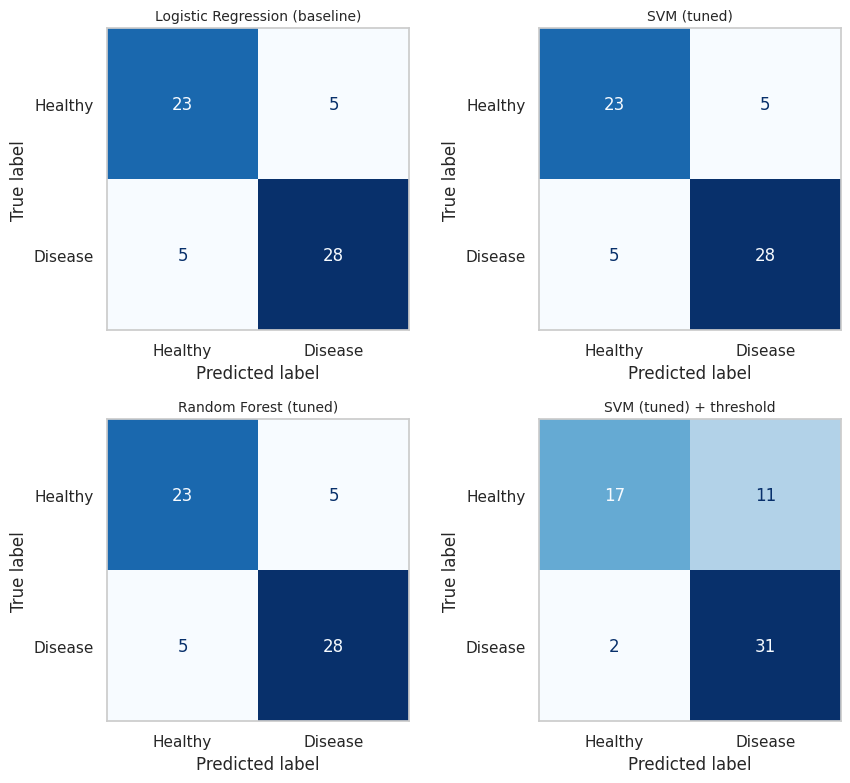

In [ ]:
results_df = pd.DataFrame(results).round(3)
display(results_df)

names = ["Logistic Regression (baseline)", "SVM (tuned)", "Random Forest (tuned)", f"{final_name} + threshold"]
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, name in zip(axes.ravel(), names):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[name][0], display_labels=["Healthy", "Disease"],
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=10)
    ax.grid(False)
save_fig("heart_confusion_matrices")
plt.show()


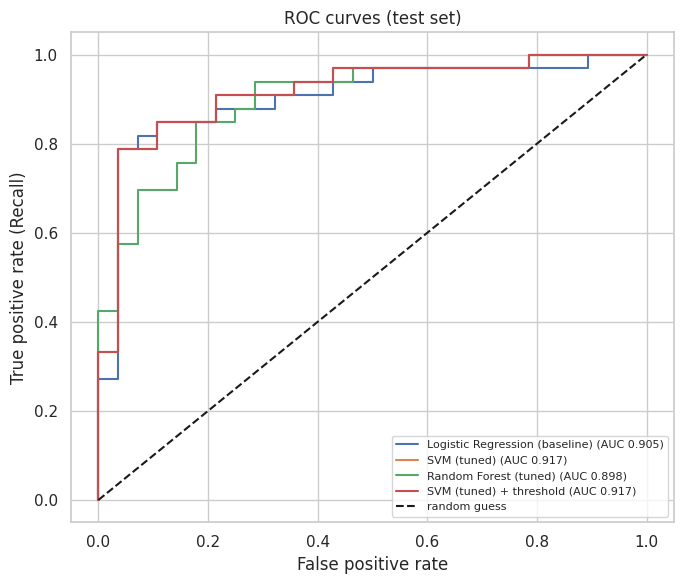

In [ ]:
plt.figure(figsize=(7, 6))
for name in names:
    fpr, tpr, _ = roc_curve(y_test, preds[name][1])
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, preds[name][1]):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (Recall)")
plt.title("ROC curves (test set)")
plt.legend(loc="lower right", fontsize=8)
save_fig("heart_roc_curves")
plt.show()


### More reliable comparison: repeated stratified cross-validation (all patients)
The test set is small, so we also compare the model setups with **5-fold CV repeated 5 times** on all patients. Each fold fits a fresh copy of the pipeline (with the tuned settings), so there is no leakage inside the loop. The tuned settings were found using the training split only, so these CV numbers are slightly optimistic for the tuned models; use them to compare models with each other, not as a final promise.

In [ ]:
from sklearn.base import clone

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
candidates = {
    "Dummy": dummy,
    "Logistic Regression": logreg,
    "SVM (tuned)": best_svm,
    "Random Forest (tuned)": best_rf,
}
rows = []
for name, model in candidates.items():
    cvres = cross_validate(clone(model), X, y, cv=rcv, scoring=["recall", "precision", "f1", "roc_auc"], n_jobs=1)
    rows.append({
        "Model": name,
        "Recall": f"{cvres['test_recall'].mean():.3f} +/- {cvres['test_recall'].std():.3f}",
        "Precision": f"{cvres['test_precision'].mean():.3f} +/- {cvres['test_precision'].std():.3f}",
        "F1": f"{cvres['test_f1'].mean():.3f} +/- {cvres['test_f1'].std():.3f}",
        "ROC-AUC": f"{cvres['test_roc_auc'].mean():.3f} +/- {cvres['test_roc_auc'].std():.3f}",
    })
display(pd.DataFrame(rows))


,Model,Recall,Precision,F1,ROC-AUC
0,Dummy,1.000 +/- 0.000,0.543 +/- 0.006,0.704 +/- 0.005,0.500 +/- 0.000
1,Logistic Regression,0.883 +/- 0.063,0.845 +/- 0.056,0.861 +/- 0.035,0.914 +/- 0.030
2,SVM (tuned),0.879 +/- 0.068,0.833 +/- 0.045,0.852 +/- 0.028,0.915 +/- 0.023
3,Random Forest (tuned),0.856 +/- 0.061,0.829 +/- 0.047,0.840 +/- 0.028,0.913 +/- 0.026


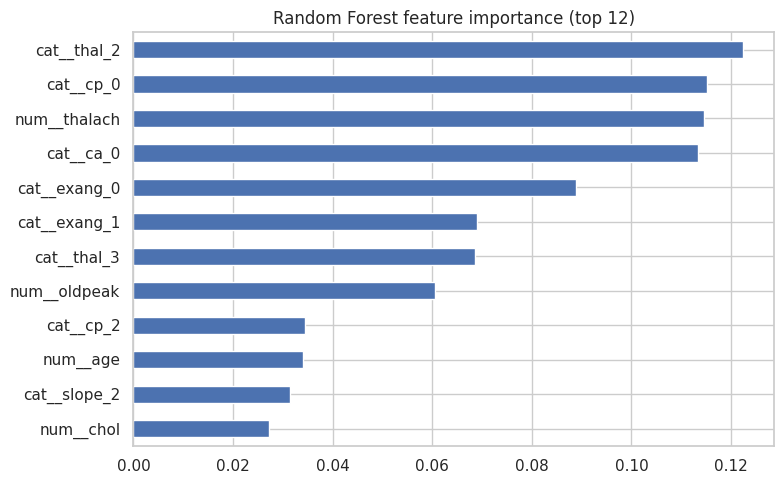

In [ ]:
if final_name.startswith("Random Forest"):
    clf = final_model.named_steps["clf"]
    imp = pd.Series(clf.feature_importances_, index=final_model.named_steps["prep"].get_feature_names_out()).sort_values().tail(12)
    imp.plot(kind="barh", figsize=(8, 5), title="Random Forest feature importance (top 12)")
else:
    # SVM has no built-in importances, so use the Random Forest for the explanation chart
    clf = best_rf.named_steps["clf"]
    imp = pd.Series(clf.feature_importances_, index=best_rf.named_steps["prep"].get_feature_names_out()).sort_values().tail(12)
    imp.plot(kind="barh", figsize=(8, 5), title="Random Forest feature importance (top 12)")
save_fig("heart_feature_importance")
plt.show()


## 8. Business impact (for the presentation)

In [ ]:
final_label = f"{final_name} + threshold"
y_hat = preds[final_label][0]
tn, fp, fn, tp = confusion_matrix(y_test, y_hat).ravel()

print(f"Model: {final_label}")
print(f"Patients in the test set:           {len(y_test)}  (with disease: {tp + fn})")
print(f"  sick patients found (TP):         {tp}  (recall {tp / (tp + fn):.1%})")
print(f"  sick patients missed (FN):        {fn}   <- the dangerous mistake")
print(f"Healthy patients sent for more tests (FP): {fp} of {tn + fp}")
print()
print(classification_report(y_test, y_hat, target_names=["Healthy", "Disease"], digits=3))


Model: SVM (tuned) + threshold
Patients in the test set:           61  (with disease: 33)
  sick patients found (TP):         31  (recall 93.9%)
  sick patients missed (FN):        2   <- the dangerous mistake
Healthy patients sent for more tests (FP): 11 of 28

              precision    recall  f1-score   support

     Healthy      0.895     0.607     0.723        28
     Disease      0.738     0.939     0.827        33

    accuracy                          0.787        61
   macro avg      0.816     0.773     0.775        61
weighted avg      0.810     0.787     0.779        61



## 9. Conclusion
**Which model was best, and why?**
All three real models are clearly better than the Dummy model (ROC-AUC 0.500), but they are not clearly different from each other.

| Model (test set, 61 patients) | Recall | Precision | F1 | ROC-AUC |
|---|---|---|---|---|
| Dummy (most frequent) | 1.000 | 0.541 | 0.702 | 0.500 |
| Logistic Regression (baseline) | 0.848 | 0.848 | 0.848 | 0.905 |
| SVM (tuned) | 0.848 | 0.848 | 0.848 | 0.917 |
| Random Forest (tuned) | 0.848 | 0.848 | 0.848 | 0.898 |
| SVM (tuned) + threshold 0.158 (final) | 0.939 | 0.738 | 0.827 | 0.917 |

The Dummy model gets a recall of 1.000 only because it predicts the positive class for every patient. In the 5x5 repeated cross-validation on all 302 patients, the three real models are also very close (ROC-AUC 0.913 to 0.915, and their recall, precision and F1 are within one standard deviation of each other). So a simple Logistic Regression is about as good as the two complex models. The SVM was chosen as the final model only because it had the highest cross-validated ROC-AUC on the training data (0.923, against 0.917 for the Random Forest).

**Trade-off**
With the usual threshold of 0.5, every real model finds 28 of the 33 positive test patients (5 missed) and wrongly flags 5 of the 28 others. With the lower threshold of 0.158, chosen on the training data with the F2 score, the final SVM finds 31 of 33 (2 missed) but wrongly flags 11 of the 28 others, and precision falls from 0.848 to 0.738. Whether this trade is worth it depends on the real cost of a missed patient against the cost of an extra check, which this project does not know.

**Limitations**
- The label may be reversed in this copy of the data (see the EDA insights). If it is, every recall and precision value above describes the healthy class.
- Only 302 distinct patients, and a test set of 61 (33 with `target = 1`). One patient moves recall by about 3 percentage points, so small differences are not reliable.
- The tuned settings and the threshold came from the training split, so the repeated cross-validation numbers are slightly optimistic for the tuned models.
- One source population and no external validation; the meaning of the coded categorical columns was not checked.
- This is a learning project. It is not a medical device and must not be used to diagnose patients.

**Future work**
- Check the label direction against the original UCI data and re-run the notebook with the correct label.
- Collect more patients and test on an external dataset.
- Calibrate the predicted probabilities and choose the threshold from real costs.
- Try feature selection and gradient boosting, and serve the model with FastAPI.